# Why 97% of Olist customers never come back — and what actually drives 1-star reviews

**Dataset:** Brazilian E-Commerce Public Dataset by Olist (Kaggle) — ~100k orders, 2016–2018, 9 relational CSV files.

**Business question:** Is it product, price or delivery that hurts the customer experience most, and what is the single cheapest fix?

**Pipeline:** MySQL (schema + queries in `/sql`) → this notebook (cleaning, features, statistics, charts) → Power BI star schema (`/data/processed`) → Excel executive summary (`/excel`).

Every definition here (late, delay days, revenue, review score) is identical to the SQL view `v_order_facts`, so numbers match across tools.

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
RAW = os.path.join(ROOT, "data", "raw")
PROCESSED = os.path.join(ROOT, "data", "processed")
IMAGES = os.path.join(ROOT, "images")
os.makedirs(PROCESSED, exist_ok=True)
os.makedirs(IMAGES, exist_ok=True)

# Chart style: thin marks, recessive grid, text never in the series colour
SURFACE, INK, INK2, GRID, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e4df", "#cfcdc6"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 11, "axes.labelcolor": INK2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 10, "text.color": INK,
})


def save(fig, name, top=1.0):
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.savefig(os.path.join(IMAGES, name), dpi=160, bbox_inches="tight")
    print("saved", name)

## 1. Load the raw files

In [2]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
orders = pd.read_csv(f"{RAW}/olist_orders_dataset.csv", parse_dates=date_cols)
customers = pd.read_csv(f"{RAW}/olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
items = pd.read_csv(f"{RAW}/olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
payments = pd.read_csv(f"{RAW}/olist_order_payments_dataset.csv")
reviews = pd.read_csv(f"{RAW}/olist_order_reviews_dataset.csv",
                      parse_dates=["review_creation_date", "review_answer_timestamp"])
products = pd.read_csv(f"{RAW}/olist_products_dataset.csv")
sellers = pd.read_csv(f"{RAW}/olist_sellers_dataset.csv", dtype={"seller_zip_code_prefix": str})
geo = pd.read_csv(f"{RAW}/olist_geolocation_dataset.csv", dtype={"geolocation_zip_code_prefix": str})
translation = pd.read_csv(f"{RAW}/product_category_name_translation.csv")
translation["product_category_name_english"] = translation["product_category_name_english"].str.strip()

for name, df in [("orders", orders), ("customers", customers), ("items", items), ("payments", payments),
                 ("reviews", reviews), ("products", products), ("sellers", sellers), ("geolocation", geo)]:
    print(f"{name:12s} {len(df):>9,} rows  {df.shape[1]:>2} cols")

orders          99,441 rows   8 cols
customers       99,441 rows   5 cols
items          112,650 rows   7 cols
payments       103,886 rows   5 cols
reviews        100,000 rows   7 cols
products        32,951 rows   9 cols
sellers          3,095 rows   4 cols
geolocation  1,000,163 rows   5 cols


## 2. Data quality checks
Same checks as `sql/03_data_quality_checks.sql`. What they found, and what I did about it:

| Issue | Count | Treatment |
|---|---|---|
| Orders not delivered (shipped, cancelled, …) | 2,963 | excluded — delivery can't be judged |
| Status `delivered` but no delivery date | 8 | excluded |
| `review_id` reused across different orders | 802 ids (827 extra rows) | composite key (review_id, order_id) |
| Orders with 2+ reviews | 555 | keep the latest answered review |
| Products with no category | 610 | labelled `unknown` |
| Categories with no English translation | 2 | Portuguese name kept |
| Sep–Dec 2016 and Sep–Oct 2018 | < 350 orders | analysis window = Jan 2017 – Aug 2018 (20 full months) |

In [3]:
print(orders["order_status"].value_counts())
print("\nMissing timestamps:\n", orders[date_cols].isna().sum())
print("\nDelivered but no delivery date:",
      ((orders.order_status == "delivered") & orders.order_delivered_customer_date.isna()).sum())
print("Duplicated review_id:", reviews.review_id.duplicated().sum(),
      "| orders with 2+ reviews:", (reviews.order_id.value_counts() > 1).sum())
print("Products without category:", products.product_category_name.isna().sum())
print("Categories without translation:",
      sorted(set(products.product_category_name.dropna()) - set(translation.product_category_name)))
print("\nOrders per month (edges are too thin to analyse):")
print(orders.set_index("order_purchase_timestamp").resample("ME").size().to_string())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing timestamps:
 order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Delivered but no delivery date: 8
Duplicated review_id: 827 | orders with 2+ reviews: 555
Products without category: 610
Categories without translation: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']

Orders per month (edges are too thin to analyse):
order_purchase_timestamp
2016-09-30       4
2016-10-31     324
2016-11-30       0
2016-12-31       1
2017-01-31     800
2017-02-28    1780
2017-03-31    2682
2017-04-30    2404
2017-05-31    3700
2017-06-30    3245
2017-07-31    4026
2017-08-31    4331
2017-09-30    4285
2017-10-31    4631
2017-11-30

## 3. Cleaning and feature engineering — one row per order
Definitions (identical to the SQL view):
* `delay_days` = delivered date − promised date in calendar days (negative = early) · `is_late` = delay_days > 0
* `delivery_days` = purchase → delivered · `promised_days` = purchase → promised date
* `handling_days` = approved → handed to carrier (seller's part) · `transit_days` = carrier → customer (carrier's part)
* `revenue` = sum of item prices (freight kept separate) · `review_score` = latest review for the order

In [4]:
# Item-level aggregation
item_agg = (items.groupby("order_id")
            .agg(revenue=("price", "sum"), freight=("freight_value", "sum"), n_items=("order_item_id", "count"),
                 n_sellers=("seller_id", "nunique"), shipping_limit_date=("shipping_limit_date", "max"))
            .reset_index())

# The order's "main" line = most expensive item -> its seller & category
main_item = (items.sort_values(["order_id", "price", "order_item_id"], ascending=[True, False, True])
             .drop_duplicates("order_id")[["order_id", "product_id", "seller_id"]])
main_item = (main_item.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
             .merge(translation, on="product_category_name", how="left")
             .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left"))
main_item["main_category"] = (main_item.product_category_name_english
                              .fillna(main_item.product_category_name).fillna("unknown"))
main_item = main_item.rename(columns={"seller_id": "main_seller_id", "seller_state": "main_seller_state"})

# Latest review per order
latest_review = (reviews.sort_values(["order_id", "review_answer_timestamp", "review_id"])
                 .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]])

# Main payment per order (highest value)
main_payment = (payments.sort_values(["order_id", "payment_value"], ascending=[True, False])
                .drop_duplicates("order_id")[["order_id", "payment_type", "payment_installments"]])
payment_total = payments.groupby("order_id", as_index=False)["payment_value"].sum()

df = (orders.merge(customers[["customer_id", "customer_unique_id", "customer_state", "customer_zip_code_prefix"]], on="customer_id")
      .merge(item_agg, on="order_id", how="left")
      .merge(main_item[["order_id", "main_seller_id", "main_seller_state", "main_category"]], on="order_id", how="left")
      .merge(latest_review, on="order_id", how="left")
      .merge(main_payment, on="order_id", how="left")
      .merge(payment_total, on="order_id", how="left"))

# Analysis population
df = df[(df.order_status == "delivered") & df.order_delivered_customer_date.notna()
        & (df.order_purchase_timestamp >= "2017-01-01") & (df.order_purchase_timestamp < "2018-09-01")].copy()

day = lambda a, b: (df[b] - df[a]).dt.total_seconds() / 86400
df["delay_days"] = (df.order_delivered_customer_date.dt.normalize() - df.order_estimated_delivery_date.dt.normalize()).dt.days
df["is_late"] = (df.delay_days > 0).astype(int)
df["delivery_days"] = day("order_purchase_timestamp", "order_delivered_customer_date").round(2)
df["promised_days"] = day("order_purchase_timestamp", "order_estimated_delivery_date").round(2)
df["handling_days"] = day("order_approved_at", "order_delivered_carrier_date").round(2)
df["transit_days"] = day("order_delivered_carrier_date", "order_delivered_customer_date").round(2)
df["shipped_after_limit"] = (df.order_delivered_carrier_date > df.shipping_limit_date).astype(int)
df["freight_ratio"] = (df.freight / df.revenue).round(4)
df["one_star"] = (df.review_score == 1).astype(int)
df["order_month"] = df.order_purchase_timestamp.dt.to_period("M").astype(str)

delay_bins = [-np.inf, -8, 0, 3, 7, 14, np.inf]
delay_labels = ["8+ days\nearly", "on time\n(0-7 days early)", "1-3 days\nlate", "4-7 days\nlate", "8-14 days\nlate", "15+ days\nlate"]
df["delay_bucket"] = pd.cut(df.delay_days, bins=delay_bins, labels=delay_labels)
speed_bins = [-np.inf, 7, 14, 21, 30, 60, np.inf]
speed_labels = ["<= 7 days", "8-14 days", "15-21 days", "22-30 days", "31-60 days", "60+ days"]
df["speed_bucket"] = pd.cut(df.delivery_days, bins=speed_bins, labels=speed_labels)

# Customer sequence: first order, cohort month
df = df.sort_values(["customer_unique_id", "order_purchase_timestamp", "order_id"])
df["order_seq"] = df.groupby("customer_unique_id").cumcount() + 1
df["customer_orders"] = df.groupby("customer_unique_id")["order_id"].transform("count")
df["cohort_month"] = df.groupby("customer_unique_id")["order_purchase_timestamp"].transform("min").dt.to_period("M").astype(str)

print(f"Analysis population: {len(df):,} delivered orders, {df.customer_unique_id.nunique():,} customers")
df[["order_id", "customer_state", "order_purchase_timestamp", "delay_days", "is_late", "delivery_days",
    "promised_days", "handling_days", "transit_days", "revenue", "review_score", "delay_bucket"]].head()

Analysis population: 96,203 delivered orders, 93,096 customers


,order_id,customer_state,order_purchase_timestamp,delay_days,is_late,delivery_days,promised_days,handling_days,transit_days,revenue,review_score,delay_bucket
52798,e22acc9c116caa3f2b7121bbb380d08e,SP,2018-05-10 10:56:27,-5,0,6.41,10.54,1.88,4.52,129.90,5,on time\n(0-7 days early)
73889,3594e05a005ac4d06a72673270ef9ec9,SP,2018-05-07 11:11:27,-5,0,3.29,7.53,1.74,1.24,18.90,4,on time\n(0-7 days early)
26460,b33ec3b699337181488304f362a6b734,SC,2017-03-10 21:05:03,-2,0,25.73,27.12,2.66,23.07,69.00,3,on time\n(0-7 days early)
98493,41272756ecddd9a9ed0180413cc22fb6,PA,2017-10-12 20:29:41,-12,0,20.04,31.15,0.97,19.05,25.99,4,8+ days\nearly
41564,d957021f1127559cd947b62533f484f7,SP,2017-11-14 19:45:42,-8,0,13.14,20.18,1.99,11.14,180.00,5,8+ days\nearly


## 4. Headline numbers
(Cross-checked against `sql/20_headline_numbers.sql` — identical.)

In [5]:
late = df[df.is_late == 1]
ontime = df[df.is_late == 0]
H = {
    "delivered_orders": len(df),
    "customers": df.customer_unique_id.nunique(),
    "revenue_brl": df.revenue.sum(),
    "avg_order_value_brl": df.revenue.mean(),
    "pct_late": 100 * df.is_late.mean(),
    "late_orders": int(df.is_late.sum()),
    "revenue_in_late_orders_brl": late.revenue.sum(),
    "avg_delivery_days": df.delivery_days.mean(),
    "avg_promised_days": df.promised_days.mean(),
    "avg_delay_days": df.delay_days.mean(),
    "avg_days_late_when_late": late.delay_days.mean(),
    "avg_review_score": df.review_score.mean(),
    "avg_score_on_time": ontime.review_score.mean(),
    "avg_score_late": late.review_score.mean(),
    "pct_one_star_on_time": 100 * ontime.one_star.mean(),
    "pct_one_star_late": 100 * late.one_star.mean(),
    "pct_of_all_one_stars_from_late_orders": 100 * late.one_star.sum() / df.one_star.sum(),
    "pct_late_orders_seller_shipped_late": 100 * late.shipped_after_limit.mean(),
    "repeat_customer_pct": 100 * (df.groupby("customer_unique_id").size() > 1).mean(),
}
headline = pd.Series(H, name="value")
print(headline.to_string())

delivered_orders                            96,203.00
customers                                   93,096.00
revenue_brl                             13,179,777.95
avg_order_value_brl                            137.00
pct_late                                         6.79
late_orders                                  6,531.00
revenue_in_late_orders_brl                 985,618.47
avg_delivery_days                               12.54
avg_promised_days                               23.65
avg_delay_days                                 -11.81
avg_days_late_when_late                         10.62
avg_review_score                                 4.14
avg_score_on_time                                4.28
avg_score_late                                   2.26
pct_one_star_on_time                             6.83
pct_one_star_late                               54.16
pct_of_all_one_stars_from_late_orders           36.62
pct_late_orders_seller_shipped_late             27.73
repeat_customer_pct         

## 5. Finding 1 — a missed promise turns a 4.3-star experience into a 1-star one
Only 6.8% of orders arrive late, but they produce 37% of all 1-star reviews.

             delay_bucket  orders  avg_score  pct_one_star  pct_4_5      revenue  pct_of_orders
           8+ days\nearly   71046       4.31          6.68    83.21 9,793,805.38          73.85
on time\n(0-7 days early)   18626       4.18          7.38    79.12 2,400,354.10          19.36
           1-3 days\nlate    1869       3.28         25.36    52.86   250,756.73           1.94
           4-7 days\nlate    1802       2.09         59.10    22.14   287,685.63           1.87
          8-14 days\nlate    1478       1.67         70.64    10.83   229,872.60           1.54
           15+ days\nlate    1382       1.72         69.03    12.30   217,303.51           1.44


saved 01_review_score_vs_delay.png


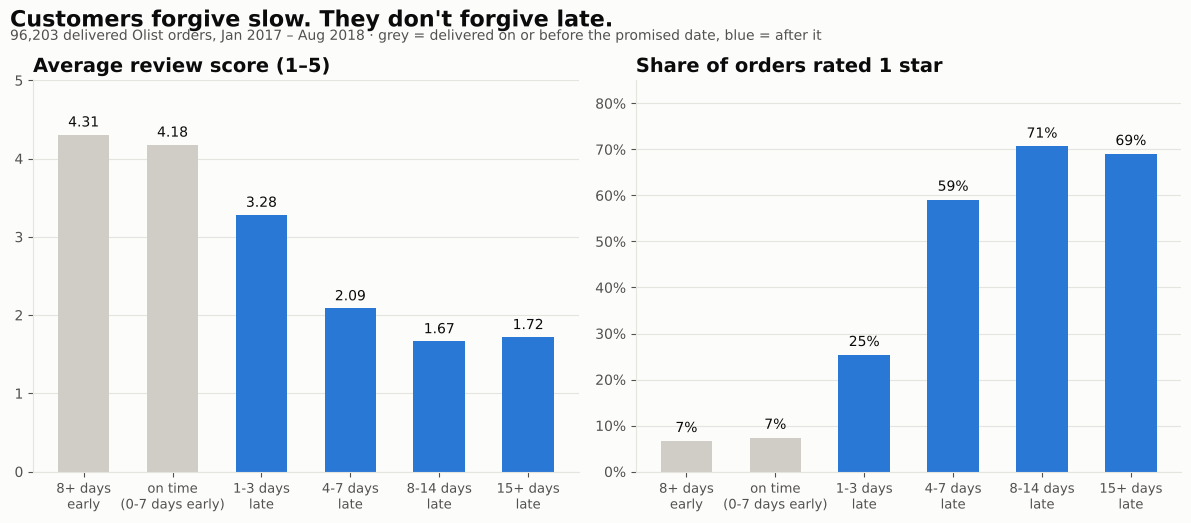

In [6]:
by_delay = (df.groupby("delay_bucket", observed=True)
            .agg(orders=("order_id", "count"), avg_score=("review_score", "mean"),
                 pct_one_star=("one_star", lambda s: 100 * s.mean()),
                 pct_4_5=("review_score", lambda s: 100 * (s >= 4).mean()),
                 revenue=("revenue", "sum")).reset_index())
by_delay["pct_of_orders"] = 100 * by_delay.orders / by_delay.orders.sum()
print(by_delay.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
x = np.arange(len(by_delay))
colors = [MUTED if "late" not in str(b) else BLUE for b in by_delay.delay_bucket]
for ax, col, title, fmt in [(axes[0], "avg_score", "Average review score (1–5)", "{:.2f}"),
                            (axes[1], "pct_one_star", "Share of orders rated 1 star", "{:.0f}%")]:
    bars = ax.bar(x, by_delay[col], width=0.58, color=colors)
    ax.set_xticks(x, [str(b) for b in by_delay.delay_bucket], fontsize=9.5)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    for b, v in zip(bars, by_delay[col]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + (0.06 if col == "avg_score" else 1.2),
                fmt.format(v), ha="center", va="bottom", fontsize=10, color=INK)
axes[0].set_ylim(0, 5)
axes[1].set_ylim(0, 85)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.text(0.01, 1.0, "Customers forgive slow. They don't forgive late.", ha="left", va="top", fontsize=16, fontweight="bold")
fig.text(0.01, 0.962, "96,203 delivered Olist orders, Jan 2017 – Aug 2018 · grey = delivered on or before the promised date, blue = after it",
         ha="left", va="top", fontsize=10, color=INK2)
save(fig, "01_review_score_vs_delay.png", top=0.94)

## 6. Finding 2 — customers judge the *promise*, not the speed
Orders that took the same number of days get very different scores depending on whether they beat the estimated date. A 22–30 day delivery that met its promise averages 3.95 stars; the same speed that missed it averages 2.57.

              avg_score_on_time  avg_score_late  orders_on_time  orders_late  score_gap
speed_bucket                                                                           
<= 7 days                  4.41            3.92           26030           62       0.49
8-14 days                  4.31            3.34           39771          316       0.96
15-21 days                 4.16            2.89           17102          535       1.27
22-30 days                 3.95            2.57            5847         2040       1.37
31-60 days                 3.66            1.83             920         3277       1.83
60+ days                   3.00            2.09               2          301       0.91


saved 02_promise_vs_speed.png


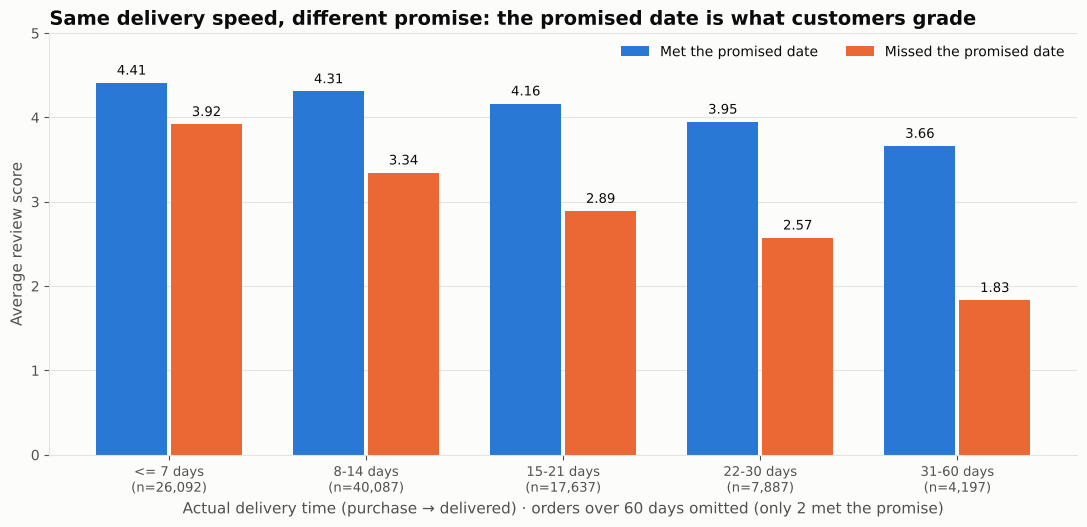

In [7]:
pvs = (df[df.review_score.notna()]
       .pivot_table(index="speed_bucket", columns="is_late", values="review_score", aggfunc=["mean", "count"], observed=True))
pvs.columns = ["avg_score_on_time", "avg_score_late", "orders_on_time", "orders_late"]
pvs["score_gap"] = pvs.avg_score_on_time - pvs.avg_score_late
print(pvs.round(2).to_string())

pvs_plot = pvs.iloc[:-1]                      # 60+ days: only 2 on-time orders -> not plotted
fig, ax = plt.subplots(figsize=(11, 5.4))
x = np.arange(len(pvs_plot)); w = 0.36
b1 = ax.bar(x - w / 2 - 0.01, pvs_plot.avg_score_on_time, width=w, color=BLUE, label="Met the promised date")
b2 = ax.bar(x + w / 2 + 0.01, pvs_plot.avg_score_late, width=w, color=ORANGE, label="Missed the promised date")
for bars in (b1, b2):
    for b in bars:
        if not np.isnan(b.get_height()):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.06, f"{b.get_height():.2f}",
                    ha="center", va="bottom", fontsize=9.5, color=INK)
ax.set_xticks(x, [f"{s}\n(n={int(a + l):,})" for s, a, l in zip(pvs_plot.index, pvs_plot.orders_on_time, pvs_plot.orders_late)], fontsize=9.5)
ax.set_xlabel("Actual delivery time (purchase → delivered) · orders over 60 days omitted (only 2 met the promise)")
ax.set_ylabel("Average review score")
ax.set_ylim(0, 5)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncol=2)
ax.set_title("Same delivery speed, different promise: the promised date is what customers grade")
save(fig, "02_promise_vs_speed.png")

## 7. Finding 3 — lateness is concentrated: specific months, routes, and the carrier leg

order_month  orders    revenue  pct_late  avg_score  pct_one_star  avg_delivery_days
    2017-01     750 111,798.36      2.93       4.18          9.47              12.65
    2017-02    1653 234,223.40      2.96       4.19          7.99              13.17
    2017-03    2546 359,198.85      4.56       4.17          8.84              12.95
    2017-04    2303 340,669.68      6.56       4.13          9.25              14.92
    2017-05    3545 489,159.25      2.99       4.22          7.79              11.32
    2017-06    3135 421,923.37      3.03       4.21          8.29              12.01
    2017-07    3872 481,604.52      2.79       4.25          7.08              11.59
    2017-08    4193 554,699.70      2.91       4.30          6.75              11.15
    2017-09    4150 607,399.67      4.39       4.25          7.54              11.85
    2017-10    4478 648,247.65      4.18       4.19          8.87              11.86
    2017-11    7288 987,648.07     12.40       3.98         13.43

saved 03_late_rate_by_month.png


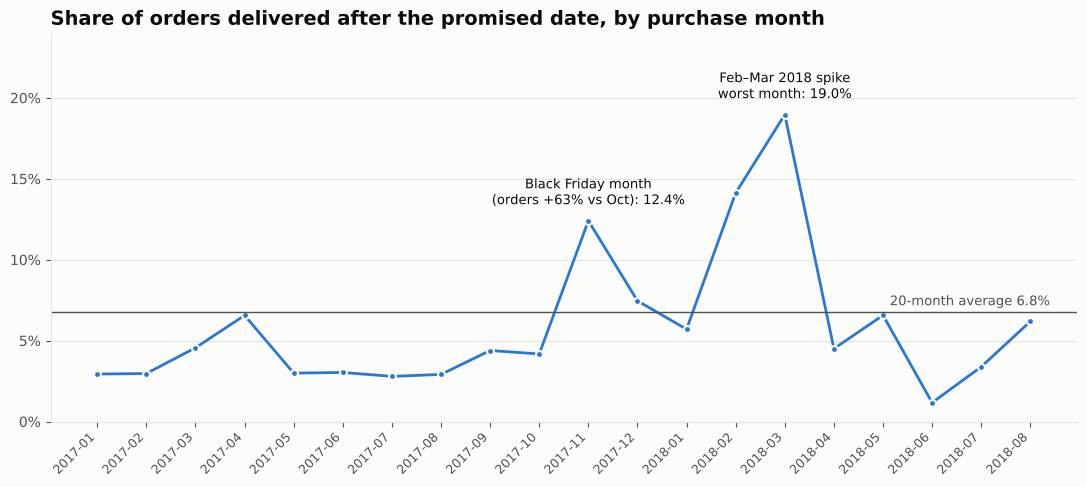

In [8]:
monthly = (df.groupby("order_month")
           .agg(orders=("order_id", "count"), revenue=("revenue", "sum"), pct_late=("is_late", lambda s: 100 * s.mean()),
                avg_score=("review_score", "mean"), pct_one_star=("one_star", lambda s: 100 * s.mean()),
                avg_delivery_days=("delivery_days", "mean")).reset_index())
print(monthly.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly.order_month, monthly.pct_late, color=BLUE, linewidth=2, marker="o", markersize=5,
        markerfacecolor=BLUE, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.axhline(H["pct_late"], color=INK2, linewidth=1, linestyle="-")
ax.text(len(monthly) - 0.6, H["pct_late"] + 0.4, f"20-month average {H['pct_late']:.1f}%", ha="right", fontsize=9.5, color=INK2)
for lbl, note, dx in [("2017-11", "Black Friday month\n(orders +63% vs Oct)", 0), ("2018-03", "Feb–Mar 2018 spike\nworst month", 0)]:
    i = monthly.index[monthly.order_month == lbl][0]
    ax.annotate(f"{note}: {monthly.pct_late[i]:.1f}%", (i, monthly.pct_late[i]), textcoords="offset points",
                xytext=(dx, 12), ha="center", fontsize=9.5, color=INK)
ax.set_xticks(range(len(monthly)), monthly.order_month, rotation=45, ha="right", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 24)
ax.grid(axis="x", visible=False)
ax.set_title("Share of orders delivered after the promised date, by purchase month")
save(fig, "03_late_rate_by_month.png")

customer_state  orders      revenue  pct_late  late_orders  avg_delivery_days  avg_promised_days  avg_score  pct_one_star  share_of_late_orders
            AL     396    78,805.73     21.46           85              24.52              32.49       3.83         15.91                  1.30
            MA     713   116,305.12     17.53          125              21.54              30.27       3.81         16.27                  1.91
            SE     332    56,288.74     15.36           51              21.44              30.60       3.89         15.66                  0.78
            PI     475    84,511.00     13.89           66              19.44              30.01       3.98         13.05                  1.01
            CE    1273   218,107.70     13.83          176              21.24              31.17       3.93         13.75                  2.69
            RR      40     7,017.77     12.50            5              29.91              45.47       3.90         12.50               

saved 04_late_rate_by_state.png


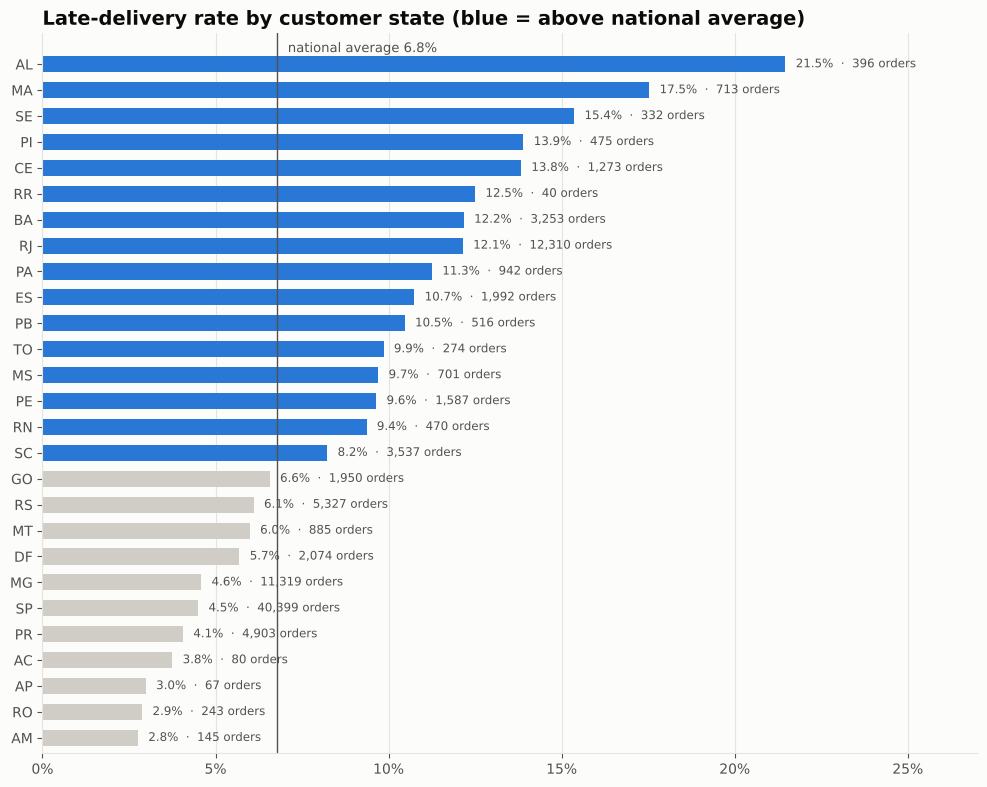

In [9]:
by_state = (df.groupby("customer_state")
            .agg(orders=("order_id", "count"), revenue=("revenue", "sum"), pct_late=("is_late", lambda s: 100 * s.mean()),
                 late_orders=("is_late", "sum"), avg_delivery_days=("delivery_days", "mean"),
                 avg_promised_days=("promised_days", "mean"), avg_score=("review_score", "mean"),
                 pct_one_star=("one_star", lambda s: 100 * s.mean()))
            .sort_values("pct_late", ascending=False).reset_index())
by_state["share_of_late_orders"] = 100 * by_state.late_orders / by_state.late_orders.sum()
print(by_state.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 8))
s = by_state.sort_values("pct_late")
colors = [BLUE if v > H["pct_late"] else MUTED for v in s.pct_late]
ax.barh(s.customer_state, s.pct_late, color=colors, height=0.62)
ax.axvline(H["pct_late"], color=INK2, linewidth=1)
ax.text(H["pct_late"] + 0.3, len(s) - 0.4, f"national average {H['pct_late']:.1f}%", fontsize=9.5, color=INK2, va="center")
for i, (v, n) in enumerate(zip(s.pct_late, s.orders)):
    ax.text(v + 0.3, i, f"{v:.1f}%  ·  {n:,} orders", va="center", fontsize=8.5, color=INK2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 27)
ax.set_ylim(-0.6, len(s) + 0.2)
ax.grid(axis="y", visible=False)
ax.set_title("Late-delivery rate by customer state (blue = above national average)")
save(fig, "04_late_rate_by_state.png")

         orders  seller_handling  carrier_transit  total  promised  pct_shipped_after_deadline
is_late                                                                                       
On time   89658             2.60             8.00  11.00     23.70                        7.50
Late       6530             5.50            27.90  33.90     22.60                       27.70

Who caused the late orders?
 shipped_after_limit
seller shipped on time, carrier was slow   72.30
seller shipped after its deadline          27.70
saved 05_delivery_stages.png


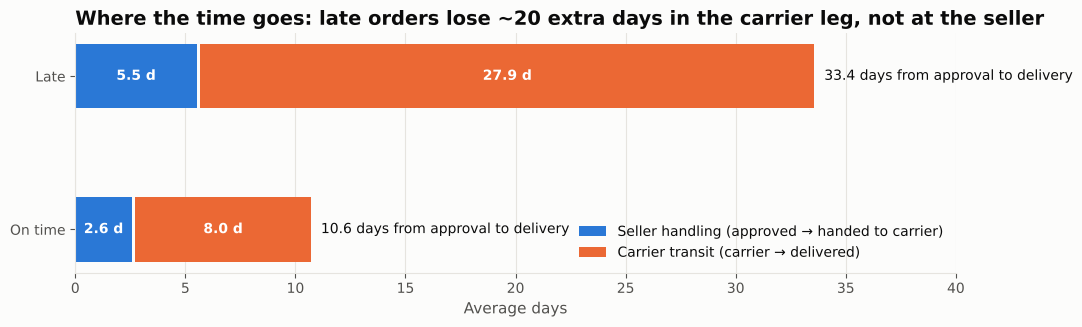

In [10]:
stages = (df.dropna(subset=["handling_days", "transit_days"])
          .groupby("is_late").agg(orders=("order_id", "count"), seller_handling=("handling_days", "mean"),
                                  carrier_transit=("transit_days", "mean"), total=("delivery_days", "mean"),
                                  promised=("promised_days", "mean"),
                                  pct_shipped_after_deadline=("shipped_after_limit", lambda s: 100 * s.mean()))
          .rename(index={0: "On time", 1: "Late"}))
print(stages.round(1).to_string())
cause = late.shipped_after_limit.map({1: "seller shipped after its deadline", 0: "seller shipped on time, carrier was slow"}).value_counts(normalize=True) * 100
print("\nWho caused the late orders?\n", cause.round(1).to_string())

fig, ax = plt.subplots(figsize=(11, 3.4))
y = np.arange(2)
ax.barh(y, stages.seller_handling, height=0.42, color=BLUE, label="Seller handling (approved → handed to carrier)")
ax.barh(y, stages.carrier_transit, left=stages.seller_handling + 0.15, height=0.42, color=ORANGE, label="Carrier transit (carrier → delivered)")
for i, (h, t) in enumerate(zip(stages.seller_handling, stages.carrier_transit)):
    ax.text(h / 2, i, f"{h:.1f} d", ha="center", va="center", fontsize=10, color="white", fontweight="bold")
    ax.text(h + 0.15 + t / 2, i, f"{t:.1f} d", ha="center", va="center", fontsize=10, color="white", fontweight="bold")
    ax.text(h + t + 0.6, i, f"{h + t:.1f} days from approval to delivery", va="center", fontsize=10, color=INK)
ax.set_yticks(y, stages.index)
ax.set_xlim(0, 40)
ax.set_xlabel("Average days")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Where the time goes: late orders lose ~20 extra days in the carrier leg, not at the seller")
save(fig, "05_delivery_stages.png")

main_seller_state customer_state  orders  late_orders  pct_late  avg_delivery_days  avg_promised_days  avg_score  cum_pct_of_late_orders   route
               SP             SP   30662         1427      4.65               7.92              17.26       4.24                   21.85 SP → SP
               SP             RJ    8137         1152     14.16              16.27              26.34       3.87                   39.49 SP → RJ
               SP             MG    7419          393      5.30              12.34              24.25       4.14                   45.51 SP → MG
               SP             BA    2304          297     12.89              19.81              29.83       3.86                   50.05 SP → BA
               SP             RS    3583          238      6.64              16.16              29.59       4.12                   53.70 SP → RS
               SP             SC    2320          222      9.57              15.83              26.02       4.02                  

saved 06_late_routes.png


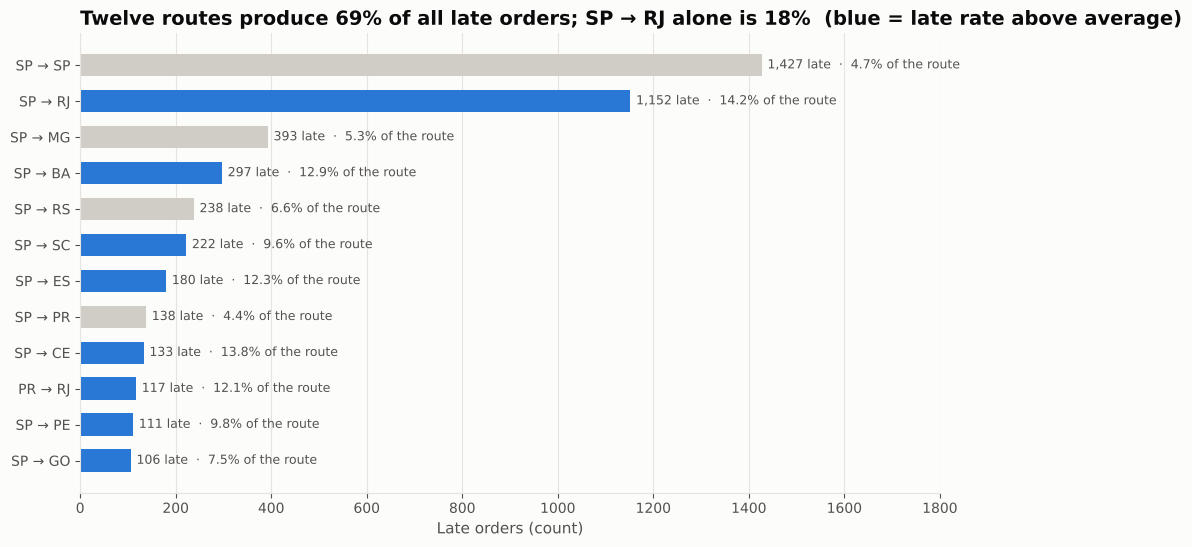

In [11]:
routes = (df.dropna(subset=["main_seller_state"])
          .groupby(["main_seller_state", "customer_state"])
          .agg(orders=("order_id", "count"), late_orders=("is_late", "sum"), pct_late=("is_late", lambda s: 100 * s.mean()),
               avg_delivery_days=("delivery_days", "mean"), avg_promised_days=("promised_days", "mean"),
               avg_score=("review_score", "mean")).reset_index())
routes = routes.sort_values("late_orders", ascending=False)
routes["cum_pct_of_late_orders"] = 100 * routes.late_orders.cumsum() / routes.late_orders.sum()
routes["route"] = routes.main_seller_state + " → " + routes.customer_state
top_routes = routes[routes.orders >= 200].head(12)
print(top_routes.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5.6))
r = top_routes.iloc[::-1]
colors = [BLUE if v > H["pct_late"] else MUTED for v in r.pct_late]
ax.barh(r.route, r.late_orders, color=colors, height=0.62)
for i, (n, p) in enumerate(zip(r.late_orders, r.pct_late)):
    ax.text(n + 12, i, f"{int(n):,} late  ·  {p:.1f}% of the route", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, 1800)
ax.set_xlabel("Late orders (count)")
ax.grid(axis="y", visible=False)
ax.set_title("Twelve routes produce 69% of all late orders; SP → RJ alone is 18%  (blue = late rate above average)")
save(fig, "06_late_routes.png")

## 8. Finding 4 — the retention problem is structural, not a delivery problem
97% of customers never place a second order, whatever happened on the first one. A late first order lowers the repeat rate from 3.0% to 2.5% — real, but small. The first order's review score does not predict a second purchase at all.

Orders per customer:
 1    97.00
2     2.75
3+    0.24

Repeat rate by first-order outcome:
                      customers  repeat_rate
is_late                                    
first order on time      86744         3.03
first order late          6352         2.52

Repeat rate by first-order review score:
               customers  repeat_rate
review_score                        
1                  9374         2.86
2                  2895         2.76
3                  7738         3.00
4                 18357         2.74
5                 54732         3.12



Cohort retention % (customers ordering again N months after their first order):
              M+1  M+2  M+3  M+4  M+5  M+6
cohort_month                              
2017-01      0.28 0.28 0.14 0.42 0.14 0.42
2017-02      0.18 0.31 0.12 0.43 0.12 0.25
2017-03      0.44 0.36 0.40 0.36 0.16 0.16
2017-04      0.62 0.22 0.18 0.27 0.27 0.35
2017-05      0.46 0.46 0.29 0.29 0.32 0.41
2017-06      0.49 0.40 0.43 0.30 0.40 0.36
2017-07      0.53 0.35 0.24 0.29 0.21 0.32
2017-08      0.69 0.35 0.27 0.35 0.52 0.30
2017-09      0.70 0.55 0.27 0.45 0.22 0.22
2017-10      0.72 0.25 0.09 0.23 0.21 0.21
2017-11      0.57 0.37 0.17 0.17 0.18 0.11
2017-12      0.21 0.28 0.34 0.26 0.21 0.17
2018-01      0.34 0.37 0.29 0.29 0.16 0.18
2018-02      0.35 0.40 0.30 0.25 0.22 0.21


saved 07_cohort_retention.png


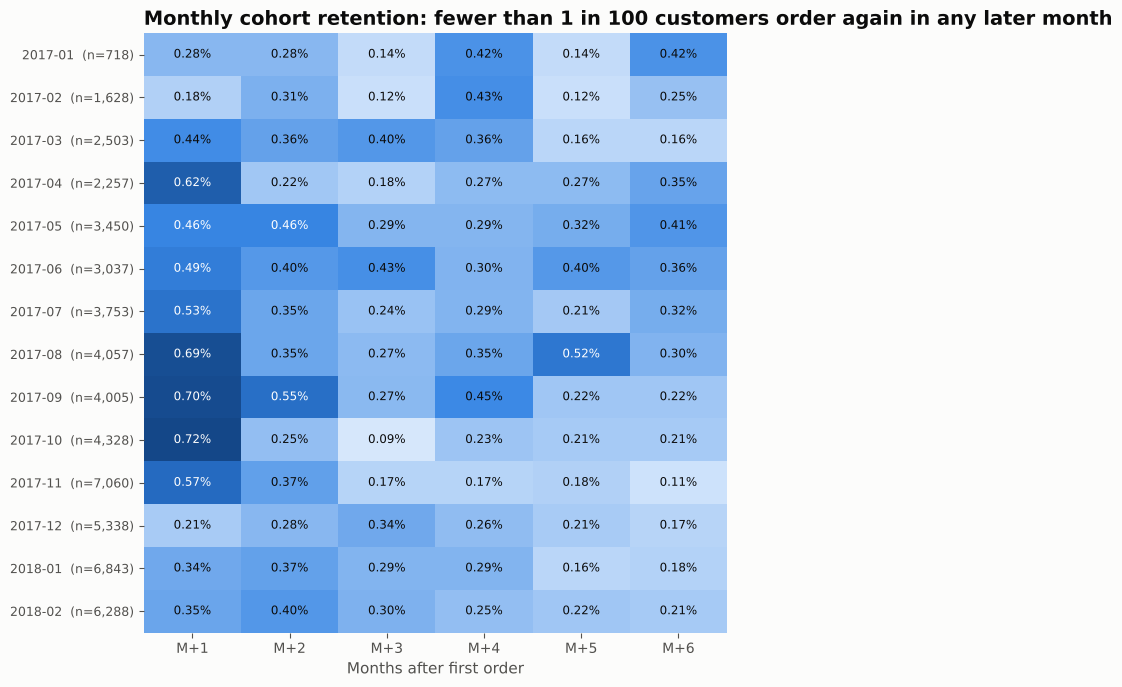

In [12]:
first = df[df.order_seq == 1].copy()
first["came_back"] = (first.customer_orders > 1).astype(int)
print("Orders per customer:\n", (df.groupby("customer_unique_id").size().clip(upper=3)
                                 .value_counts(normalize=True).sort_index().mul(100).round(2).rename({3: "3+"}).to_string()))
rep_late = first.groupby("is_late").came_back.agg(customers="count", repeat_rate=lambda s: 100 * s.mean()).rename(index={0: "first order on time", 1: "first order late"})
rep_score = first.dropna(subset=["review_score"]).groupby("review_score").came_back.agg(customers="count", repeat_rate=lambda s: 100 * s.mean())
print("\nRepeat rate by first-order outcome:\n", rep_late.round(2).to_string())
print("\nRepeat rate by first-order review score:\n", rep_score.round(2).to_string())

# Cohort retention (customers acquired each month who ordered again N months later)
coh = df[["customer_unique_id", "cohort_month", "order_month"]].copy()
coh["offset"] = ((pd.PeriodIndex(coh.order_month, freq="M") - pd.PeriodIndex(coh.cohort_month, freq="M"))
                 .map(lambda x: x.n))
size = coh.groupby("cohort_month").customer_unique_id.nunique()
ret = (coh[coh.offset.between(1, 6)].groupby(["cohort_month", "offset"]).customer_unique_id.nunique()
       .unstack("offset").reindex(size.index).fillna(0))
ret = ret.div(size, axis=0) * 100
ret.columns = [f"M+{c}" for c in ret.columns]
ret = ret.loc["2017-01":"2018-02"]          # cohorts with at least 6 months of follow-up
print("\nCohort retention % (customers ordering again N months after their first order):")
print(ret.round(2).to_string())

fig, ax = plt.subplots(figsize=(7.5, 7))
im = ax.imshow(ret.values, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", [SURFACE] + BLUES), vmin=0, vmax=0.8, aspect="auto")
ax.set_xticks(range(ret.shape[1]), ret.columns)
ax.set_yticks(range(ret.shape[0]), [f"{c}  (n={size[c]:,})" for c in ret.index], fontsize=9)
for i in range(ret.shape[0]):
    for j in range(ret.shape[1]):
        v = ret.values[i, j]
        ax.text(j, i, f"{v:.2f}%", ha="center", va="center", fontsize=8.5, color="white" if v > 0.45 else INK)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title("Monthly cohort retention: fewer than 1 in 100 customers order again in any later month")
ax.set_xlabel("Months after first order")
save(fig, "07_cohort_retention.png")

## 9. Finding 5 — multi-item and multi-seller orders are a second, separate problem
Lateness is the biggest driver of 1-star reviews, but it is not the only one. Splitting orders by how many items and how many sellers they contain shows a second effect that is independent of lateness: multi-item orders are *less* often late, yet get far more 1-star reviews. The most likely explanation is split or partial deliveries (one parcel arrives, the other does not).

In [13]:
m = df.dropna(subset=["review_score", "delivery_days"]).copy()
m["days_late"] = m.delay_days.clip(lower=0)
groups = {"single item": m.n_items == 1, "2+ items (any)": m.n_items > 1, "of which 2+ sellers": m.n_sellers > 1}

def describe(sub):
    return pd.Series({"orders": len(sub), "pct_late": 100 * sub.is_late.mean(), "pct_one_star": 100 * sub.one_star.mean(),
                      "avg_score": sub.review_score.mean(),
                      "one_star_on_time": 100 * sub[sub.is_late == 0].one_star.mean(), "one_star_late": 100 * sub[sub.is_late == 1].one_star.mean()})

composition = pd.DataFrame({k: describe(m[v]) for k, v in groups.items()}).T.round(1)
composition["one_star_vs_single_item"] = (composition.pct_one_star / composition.loc["single item", "pct_one_star"]).round(1)
print(composition.to_string())

                       orders  pct_late  pct_one_star  avg_score  one_star_on_time  one_star_late  one_star_vs_single_item
single item         86,598.00      7.00          8.70       4.20              5.40          53.80                     1.00
2+ items (any)       9,605.00      5.30         21.70       3.60             19.60          58.70                     2.50
of which 2+ sellers  1,272.00      1.00         36.10       2.80             35.70          69.20                     4.10


**Reading it:** 1-star reviews on 8.7% of single-item orders vs 21.7% of multi-item orders (2.5×) and 36.1% of multi-seller orders (4.1×) — even though multi-item orders are late less often (5.3% vs 7.0%). The gap is there among on-time orders too (`one_star_on_time` column), so it is not lateness in disguise. It deserves its own investigation (partial deliveries, one review covering several parcels).

saved 08_one_star_rate_by_days_late.png


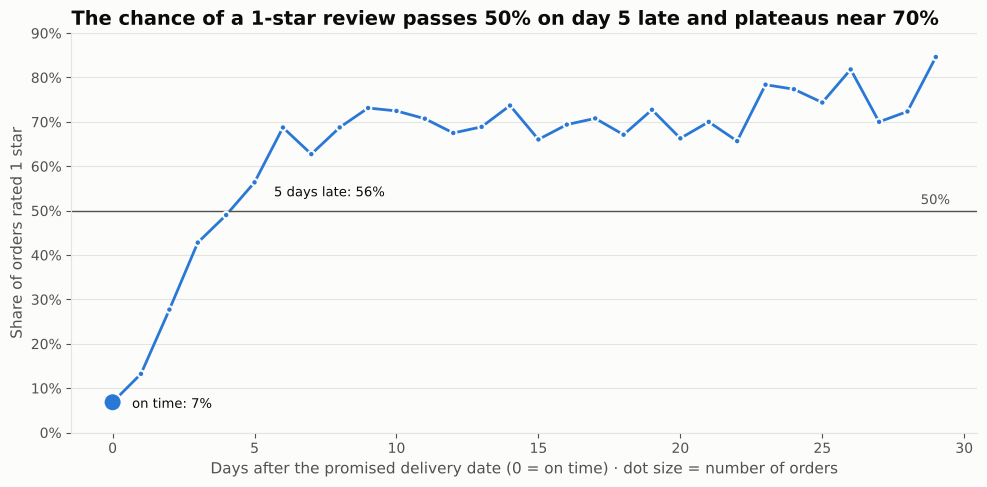

In [14]:
# Share of orders rated 1 star by days after the promised date — the observed curve, for the memo
observed = m[m.days_late <= 30].groupby("days_late").one_star.agg(["mean", "count"])
observed.columns = ["p_one_star_observed", "orders"]
curve = observed

obs = curve[curve.orders >= 30]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(obs.index, 100 * obs.p_one_star_observed, color=BLUE, linewidth=2, zorder=2)
ax.scatter(obs.index, 100 * obs.p_one_star_observed, s=np.clip(obs.orders / 40, 22, 170), color=BLUE,
           edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.axhline(50, color=INK2, linewidth=1)
ax.text(29.5, 51.5, "50%", ha="right", fontsize=9.5, color=INK2)
ax.annotate(f"on time: {100 * obs.p_one_star_observed.iloc[0]:.0f}%", (0, 100 * obs.p_one_star_observed.iloc[0]),
            textcoords="offset points", xytext=(14, -4), fontsize=9.5, color=INK)
ax.annotate(f"5 days late: {100 * obs.p_one_star_observed.loc[5]:.0f}%", (5, 100 * obs.p_one_star_observed.loc[5]),
            textcoords="offset points", xytext=(14, -10), fontsize=9.5, color=INK)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Days after the promised delivery date (0 = on time) · dot size = number of orders")
ax.set_ylabel("Share of orders rated 1 star")
ax.set_ylim(0, 90)
ax.grid(axis="x", visible=False)
ax.set_title("The chance of a 1-star review passes 50% on day 5 late and plateaus near 70%")
save(fig, "08_one_star_rate_by_days_late.png")

## 10. Sizing the fix — inputs for the Excel what-if
Two levers, both quantified from the data above:
1. **Operational:** cut the late share (carrier SLA on the worst routes). Every late order moved to on-time avoids a 1-star review 47 percentage points of the time.
2. **Promise:** add a buffer to the estimated date on at-risk routes. Because customers grade the promise, a late order that becomes "on time" after a longer promise behaves like an on-time order (the rows of Finding 2). The table below shows what share of today's late orders a given buffer would have rescued, for three scopes: only the 12 worst routes, those routes plus the Nov–Mar peak on every route, and every order.

In [15]:
annual_orders = len(df) / 20 * 12
late = df[df.is_late == 1].copy()
worst_routes = set(zip(top_routes.main_seller_state, top_routes.customer_state))          # the 12 routes charted above
late["on_worst_route"] = [(a, b) in worst_routes for a, b in zip(late.main_seller_state, late.customer_state)]
late["in_peak_season"] = late.order_purchase_timestamp.dt.month.isin([11, 12, 1, 2, 3])    # Nov-Mar

def rescued(mask, k):
    """share of ALL late orders that a k-day buffer, applied only where mask is True, would have made on-time"""
    return 100 * ((late.delay_days <= k) & mask).sum() / len(late)

rescue = pd.DataFrame({"buffer_days": range(1, 15)})
rescue["pct_rescued_12_worst_routes"] = [rescued(late.on_worst_route, k) for k in rescue.buffer_days]
rescue["pct_rescued_routes_plus_nov_mar"] = [rescued(late.on_worst_route | late.in_peak_season, k) for k in rescue.buffer_days]
rescue["pct_rescued_all_orders"] = [rescued(pd.Series(True, index=late.index), k) for k in rescue.buffer_days]
for scope in ["12_worst_routes", "routes_plus_nov_mar", "all_orders"]:
    rescue[f"late_orders_rescued_per_year_{scope}"] = (annual_orders * H["pct_late"] / 100 * rescue[f"pct_rescued_{scope}"] / 100).round(0)
    rescue[f"one_star_avoided_per_year_{scope}"] = (rescue[f"late_orders_rescued_per_year_{scope}"] * (H["pct_one_star_late"] - H["pct_one_star_on_time"]) / 100).round(0)
print(f"Annualised delivered orders: {annual_orders:,.0f}")
print(f"Late orders on the 12 worst routes: {100 * late.on_worst_route.mean():.1f}% of all late orders; in Nov-Mar: {100 * late.in_peak_season.mean():.1f}%\n")
print(rescue[["buffer_days", "pct_rescued_12_worst_routes", "pct_rescued_routes_plus_nov_mar", "pct_rescued_all_orders",
              "one_star_avoided_per_year_12_worst_routes", "one_star_avoided_per_year_routes_plus_nov_mar", "one_star_avoided_per_year_all_orders"]].round(1).to_string(index=False))

whatif_inputs = pd.Series({
    "annual_delivered_orders": round(annual_orders),
    "current_late_share_pct": H["pct_late"],
    "one_star_rate_late_pct": H["pct_one_star_late"],
    "one_star_rate_on_time_pct": H["pct_one_star_on_time"],
    "avg_score_late": H["avg_score_late"],
    "avg_score_on_time": H["avg_score_on_time"],
    "repeat_rate_first_order_late_pct": rep_late.loc["first order late", "repeat_rate"],
    "repeat_rate_first_order_on_time_pct": rep_late.loc["first order on time", "repeat_rate"],
    "avg_order_value_brl": H["avg_order_value_brl"],
    "revenue_in_late_orders_brl": H["revenue_in_late_orders_brl"],
}, name="value")
print("\nWhat-if inputs:\n", whatif_inputs.round(2).to_string())

Annualised delivered orders: 57,722
Late orders on the 12 worst routes: 69.1% of all late orders; in Nov-Mar: 63.7%

 buffer_days  pct_rescued_12_worst_routes  pct_rescued_routes_plus_nov_mar  pct_rescued_all_orders  one_star_avoided_per_year_12_worst_routes  one_star_avoided_per_year_routes_plus_nov_mar  one_star_avoided_per_year_all_orders
           1                         9.20                            11.10                   12.60                                     170.00                                         206.00                                234.00
           2                        15.20                            18.40                   21.00                                     281.00                                         340.00                                389.00
           3                        20.40                            24.80                   28.60                                     378.00                                         460.00              

## 11. Export — star schema for Power BI, tables for Excel

In [16]:
# --- fact_orders (order grain) ---
fact_cols = ["order_id", "customer_unique_id", "customer_state", "customer_zip_code_prefix", "main_seller_id",
             "main_seller_state", "main_category", "order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date",
             "delay_days", "is_late", "delivery_days", "promised_days", "handling_days", "transit_days",
             "shipped_after_limit", "revenue", "freight", "n_items", "n_sellers", "review_score", "one_star",
             "payment_type", "payment_installments", "payment_value", "delay_bucket", "speed_bucket",
             "order_seq", "customer_orders", "cohort_month"]
fact = df[fact_cols].copy()
fact["purchase_date"] = fact.order_purchase_timestamp.dt.date
fact["order_month"] = df.order_month
fact["delay_bucket"] = fact.delay_bucket.astype(str).str.replace("\n", " ")
fact["speed_bucket"] = fact.speed_bucket.astype(str)
# helper columns for Power BI (sort keys, labels, route)
fact["delay_bucket_sort"] = df.delay_bucket.cat.codes + 1
fact["speed_bucket_sort"] = df.speed_bucket.cat.codes + 1
fact["late_flag_label"] = np.where(fact.is_late == 1, "Missed the promised date", "Met the promised date")
fact["route"] = fact.main_seller_state.fillna("?") + " → " + fact.customer_state
fact["is_first_order"] = (fact.order_seq == 1).astype(int)
fact.to_csv(f"{PROCESSED}/fact_orders.csv", index=False)

# --- fact_order_items (item grain, only orders in the analysis population) ---
fi = items[items.order_id.isin(df.order_id)].merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
fi = fi.merge(translation, on="product_category_name", how="left")
fi["category"] = fi.product_category_name_english.fillna(fi.product_category_name).fillna("unknown")
fi[["order_id", "order_item_id", "product_id", "seller_id", "shipping_limit_date", "price", "freight_value", "category"]].to_csv(f"{PROCESSED}/fact_order_items.csv", index=False)

# --- geography: average coordinates per zip prefix and per state (outliers outside Brazil removed) ---
g = geo[(geo.geolocation_lat.between(-34, 6)) & (geo.geolocation_lng.between(-74, -34))]
zip_geo = g.groupby("geolocation_zip_code_prefix").agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean")).reset_index().rename(columns={"geolocation_zip_code_prefix": "zip_code_prefix"})
state_geo = g.groupby("geolocation_state").agg(lat=("geolocation_lat", "median"), lng=("geolocation_lng", "median")).reset_index().rename(columns={"geolocation_state": "state"})

STATE_NAMES = {"AC": "Acre", "AL": "Alagoas", "AP": "Amapá", "AM": "Amazonas", "BA": "Bahia", "CE": "Ceará", "DF": "Distrito Federal",
               "ES": "Espírito Santo", "GO": "Goiás", "MA": "Maranhão", "MT": "Mato Grosso", "MS": "Mato Grosso do Sul",
               "MG": "Minas Gerais", "PA": "Pará", "PB": "Paraíba", "PR": "Paraná", "PE": "Pernambuco", "PI": "Piauí",
               "RJ": "Rio de Janeiro", "RN": "Rio Grande do Norte", "RS": "Rio Grande do Sul", "RO": "Rondônia", "RR": "Roraima",
               "SC": "Santa Catarina", "SP": "São Paulo", "SE": "Sergipe", "TO": "Tocantins"}
REGION = {"North": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"], "Northeast": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
          "Central-West": ["DF", "GO", "MT", "MS"], "Southeast": ["ES", "MG", "RJ", "SP"], "South": ["PR", "RS", "SC"]}
state_region = {s: r for r, ss in REGION.items() for s in ss}
dim_state = pd.DataFrame({"state": list(STATE_NAMES), "state_name": list(STATE_NAMES.values())})
dim_state["region"] = dim_state.state.map(state_region)
dim_state["country"] = "Brazil"
dim_state["map_location"] = dim_state.state_name + ", Brazil"
dim_state = dim_state.merge(state_geo, on="state", how="left")
dim_state.to_csv(f"{PROCESSED}/dim_state.csv", index=False)

# --- dim_customer (person grain) ---
dc = (df.groupby("customer_unique_id")
      .agg(customer_state=("customer_state", "first"), zip_code_prefix=("customer_zip_code_prefix", "first"),
           first_order_date=("order_purchase_timestamp", "min"), last_order_date=("order_purchase_timestamp", "max"),
           orders=("order_id", "count"), revenue=("revenue", "sum"), first_order_late=("is_late", "first"))
      .reset_index())
dc["is_repeat_customer"] = (dc.orders > 1).astype(int)
dc["cohort_month"] = dc.first_order_date.dt.to_period("M").astype(str)
dc["orders_bucket"] = np.select([dc.orders == 1, dc.orders == 2], ["1 order", "2 orders"], "3+ orders")
dc["first_order_late_label"] = np.where(dc.first_order_late == 1, "First order late", "First order on time")
dc = dc.merge(df[df.order_seq == 1][["customer_unique_id", "review_score"]].rename(columns={"review_score": "first_order_score"}), on="customer_unique_id", how="left")
dc = dc.merge(zip_geo, on="zip_code_prefix", how="left")
dc.to_csv(f"{PROCESSED}/dim_customer.csv", index=False)

# --- dim_seller ---
so = items[items.order_id.isin(df.order_id)][["order_id", "seller_id"]].drop_duplicates().merge(df[["order_id", "is_late", "review_score", "shipped_after_limit", "revenue"]], on="order_id")
ds = (so.groupby("seller_id").agg(orders=("order_id", "count"), late_orders=("is_late", "sum"), avg_review_score=("review_score", "mean"),
                                   pct_shipped_after_deadline=("shipped_after_limit", lambda s: 100 * s.mean()), revenue=("revenue", "sum")).reset_index())
ds["pct_late"] = 100 * ds.late_orders / ds.orders
ds = sellers.merge(ds, on="seller_id", how="left").merge(zip_geo.rename(columns={"zip_code_prefix": "seller_zip_code_prefix"}), on="seller_zip_code_prefix", how="left")
ds.to_csv(f"{PROCESSED}/dim_seller.csv", index=False)

# --- dim_product ---
dp = products.rename(columns={"product_name_lenght": "product_name_length", "product_description_lenght": "product_description_length"})
dp = dp.merge(translation, on="product_category_name", how="left")
dp["category"] = dp.product_category_name_english.fillna(dp.product_category_name).fillna("unknown")
top15 = (fi.groupby("category").price.sum().sort_values(ascending=False).head(15).index)
dp["category_top15"] = np.where(dp.category.isin(top15), dp.category, "Other")
dp.to_csv(f"{PROCESSED}/dim_product.csv", index=False)

# --- dim_date ---
dd = pd.DataFrame({"date": pd.date_range("2016-09-01", "2018-10-31", freq="D")})
dd["year"] = dd.date.dt.year; dd["month"] = dd.date.dt.month; dd["month_name"] = dd.date.dt.strftime("%b")
dd["year_month"] = dd.date.dt.strftime("%Y-%m"); dd["quarter"] = "Q" + dd.date.dt.quarter.astype(str)
dd["weekday"] = dd.date.dt.strftime("%a"); dd["is_weekend"] = dd.date.dt.weekday.ge(5).astype(int)
dd["in_analysis_window"] = dd.date.between("2017-01-01", "2018-08-31").astype(int)
dd.to_csv(f"{PROCESSED}/dim_date.csv", index=False)

# --- cohort retention, long format (for the Power BI matrix) ---
coh_long = (coh[coh.offset.between(1, 12)].groupby(["cohort_month", "offset"]).customer_unique_id.nunique().reset_index()
            .rename(columns={"customer_unique_id": "active_customers", "offset": "month_offset"}))
coh_long["cohort_customers"] = coh_long.cohort_month.map(size)
coh_long["retention_pct"] = coh_long.active_customers / coh_long.cohort_customers
coh_long.to_csv(f"{PROCESSED}/cohort_retention.csv", index=False)

# --- summary tables for Excel / README ---
headline.to_csv(f"{PROCESSED}/summary_headline.csv", header=True)
whatif_inputs.to_csv(f"{PROCESSED}/summary_whatif_inputs.csv", header=True)
rescue.to_csv(f"{PROCESSED}/summary_promise_buffer_rescue.csv", index=False)
by_delay.assign(delay_bucket=by_delay.delay_bucket.astype(str).str.replace("\n", " ")).to_csv(f"{PROCESSED}/summary_by_delay_bucket.csv", index=False)
pvs.reset_index().to_csv(f"{PROCESSED}/summary_promise_vs_speed.csv", index=False)
monthly.to_csv(f"{PROCESSED}/summary_by_month.csv", index=False)
by_state.merge(dim_state[["state", "state_name", "region"]], left_on="customer_state", right_on="state").drop(columns="state").to_csv(f"{PROCESSED}/summary_by_state.csv", index=False)
stages.reset_index().to_csv(f"{PROCESSED}/summary_delivery_stages.csv", index=False)
routes.head(30).to_csv(f"{PROCESSED}/summary_late_routes.csv", index=False)
rep_late.reset_index().rename(columns={"is_late": "first_order"}).to_csv(f"{PROCESSED}/summary_repeat_by_first_order.csv", index=False)
rep_score.reset_index().to_csv(f"{PROCESSED}/summary_repeat_by_first_score.csv", index=False)
ret.round(3).to_csv(f"{PROCESSED}/summary_cohort_retention.csv")
cat = (fi.merge(df[["order_id", "is_late", "review_score", "one_star"]], on="order_id")
       .groupby("category").agg(orders=("order_id", "nunique"), items_sold=("order_item_id", "count"), revenue=("price", "sum"),
                                freight=("freight_value", "sum"), pct_late=("is_late", lambda s: 100 * s.mean()),
                                avg_score=("review_score", "mean"), pct_one_star=("one_star", lambda s: 100 * s.mean()))
       .sort_values("revenue", ascending=False).reset_index())
cat["pct_of_revenue"] = 100 * cat.revenue / cat.revenue.sum()
cat["freight_pct_of_price"] = 100 * cat.freight / cat.revenue
cat.to_csv(f"{PROCESSED}/summary_by_category.csv", index=False)

for f in sorted(os.listdir(PROCESSED)):
    print(f"{f:45s} {os.path.getsize(os.path.join(PROCESSED, f)) / 1e6:6.2f} MB")

cohort_retention.csv                            0.01 MB
dim_customer.csv                               15.86 MB
dim_date.csv                                    0.03 MB
dim_product.csv                                 4.07 MB
dim_seller.csv                                  0.42 MB
dim_state.csv                                   0.00 MB
fact_order_items.csv                           16.07 MB
fact_orders.csv                                37.09 MB
summary_by_category.csv                         0.01 MB
summary_by_delay_bucket.csv                     0.00 MB
summary_by_month.csv                            0.00 MB
summary_by_state.csv                            0.00 MB
summary_cohort_retention.csv                    0.00 MB
summary_delivery_stages.csv                     0.00 MB
summary_headline.csv                            0.00 MB
summary_late_routes.csv                         0.00 MB
summary_promise_buffer_rescue.csv               0.00 MB
summary_promise_vs_speed.csv                    

## 12. Conclusions

1. **Late delivery is the single biggest driver of bad reviews.** 6.8% of orders arrive after the promised date, but they generate 37% of all 1-star reviews. Average score: 4.28 on time vs 2.26 late. Being just 1–3 days late drops the score to 3.28; at 4–7 days late, 59% of orders get 1 star.
2. **Customers grade the promise, not the speed.** Orders that took 22–30 days but met the promise scored 3.95; the same speed that missed it scored 2.57. The estimate is padded by ~12 days on average and still fails on specific routes — it is uniform, not route-aware.
3. **Lateness is concentrated.** 12 seller→customer routes produce 69% of late orders (SP→RJ alone 18%, with a 14% late rate). It spikes around Black Friday (12%) and Feb–Mar 2018 (14–19%). In 72% of late orders the seller shipped on time — the carrier leg is where ~20 extra days are lost.
4. **Multi-item and multi-seller orders are a second, separate problem.** They are less often late, yet get 1-star reviews 2.5× (multi-item) and 4.1× (multi-seller) as often as single-item orders — consistent with split or partial deliveries.
5. **Retention is structural.** 97% of customers never reorder, regardless of delivery or review score. A late first order lowers repeat probability from 3.0% to 2.5% — real but small. Fixing delivery will protect reputation, not create repeat buyers; retention needs a different lever.

**Recommendation (cheapest first):**
* Make the delivery promise route-aware: add a buffer on the 12 worst routes and during Nov–Mar. A 7-day buffer on the 12 routes alone would have turned 40% of all late orders into on-time ones; extended to the Nov–Mar peak on every route, 49%; applied everywhere, 56% — all at zero logistics cost. A/B test it against conversion.
* Put a carrier SLA on deliveries to Rio de Janeiro and the nine Northeast states: 22% of orders but 40% of the late ones (12.4% late rate vs 4.5% in São Paulo).
* Stop treating delivery as a retention lever; measure it on review score and 1-star rate instead.